# Working with maps in Plotnine

## Maps are cool

Over the last 10 years I've taught a graduate level applied statistics course and at some point along the way I thought we should cover maps. Yes, I know, "maps" != "statistics", but. . . maps are cool.

For my students in the field of environmental science, using maps to visualize their work is a relevant skill. For the rest of us? Well. . . maps are cool. It ends up, the R programming language has some excellent tools for generating maps. For many of my students, this course is their first experience using code to carryout data analyses and visualizations---for statistical methods, R is still a logical choice. There are some excellent packages in R built around the "Tidyverse" that make learning data manipulation (dplyr) and visualization (ggplot2) a great first language. 

While I still use R for my course, much of my professional work has moved to Python. 

## R to Python 

R is still a popular language; this is seen in several online indexes including [TIOBE](https://www.tiobe.com/tiobe-index/), where R is ranked #7---up from #12 just a year ago. R is not going away. Of course, Python is ranked #1 and has been the most popular general purpose language for at least five years. Two Python packages that facilitated my adoption of Python are Polars for data manipulation and Plotnine for visualizations. 

The Polars' community has adopted a saying that people *"come for the speed and stay for the API."* Personally, I came for the API. It can't replace Pandas (yet), but for data manipulation and transformation, it's my preferred Python tool when working with data.

And Plotnine? From the [matplotlib.org site](https://matplotlib.org/)

>plotnine is an implementation of a grammar of graphics in Python. The grammar allows users to compose plots by explicitly mapping data to the visual objects that make up the plot.

The syntax is very similar to [ggplot2](https://ggplot2.tidyverse.org/). 
I love working in ggplot2 and Plotnine allows me to take those skills directly into a Python environment. 

## Choropleth Maps in Python  

Until I had worked through this process, if I needed to make a map, I would have done it in R. I knew the framework that leveraged ggplot2 and I was able to get reproducible results. Unfortunately, it wasn't a drop-in replacement. I've worked to document the equivalent workflow below that allows a user to build choropleth maps in Python using Plotnine. 

>A choropleth map is a thematic map that uses color, shading, or patterns (pseudocolor) to represent statistical or numerical data aggregated over predefined geographic regions, such as states, counties, or countries
>---Wikipedia

## Required packages for this notebook

In [1]:
import os
import polars as pl
import pandas as pd

import geopandas as gpd 

import pygris
from pygris.utils import shift_geometry
from pygris.data import get_census

from dotenv import load_dotenv
load_dotenv()

census_key = os.getenv("CENSUS_API_KEY")

from plotnine import *

Info on selected packages from above.

[geopandas](https://geopandas.org/en/stable/index.html)

>The goal of GeoPandas is to make working with geospatial data in python easier. It combines the capabilities of pandas and shapely, providing geospatial operations in pandas and a high-level interface to multiple geometries to shapely. GeoPandas enables you to easily do operations in python that would otherwise require a spatial database such as PostGIS.

[pygris](https://walker-data.com/pygris/)  

>pygris is a Python package to help users access US Census Bureau TIGER/Line and cartographic boundary shapefiles and load them into Python as GeoDataFrames. The goal of the package is to make it simple to access US Census geographic data; data can be acquired with a single function for a given geography (e.g. tracts() for Census tracts) along with a few options.

A list of [pygris datasets are available in the online documentation.](https://walker-data.com/pygris/01-basic-usage/)

Not used in this notebook, but often cited in online examples

[geodatasets](https://geodatasets.readthedocs.io/en/latest/introduction.html)

>The geodatasets contains an API on top of a JSON with metadata of externally hosted datasets containing geospatial information useful for illustrative and educational purposes.

[dotenv](https://pypi.org/project/python-dotenv/)

>`load_dotenv()` reads variables from a .env file and sets them in os.environ

## Making a choropleth map

In the example below, I'll show the steps to create a choropleth with each states population being shown with a color scale.

### Step 1: Create a base map

For this example, the we can use `pygris.states()` to download US state boundaries from the U.S. Census. Two arguments used in the cell below:

- **cb=True** gives clean cartographic shapes
- **resolution='20m'** keeps the file lightweight and automatically excludes small island territories

In [2]:
states_gdf = pygris.states(cb=True, resolution="20m", cache=True)

states_gdf.head()

Using the default year of 2024


,STATEFP,STATENS,GEOIDFQ,GEOID,STUSPS,NAME,LSAD,ALAND,AWATER,geometry
0,48,01779801,0400000US48,48,TX,Texas,00,676656702022,19011620342,"POLYGON ((-106.62344 31.91403, -106.63011 31.9..."
1,06,01779778,0400000US06,06,CA,California,00,403673433805,20291632828,"MULTIPOLYGON (((-118.59397 33.4672, -118.48478..."
2,21,01779786,0400000US21,21,KY,Kentucky,00,102266755818,2384136185,"POLYGON ((-89.54443 36.57451, -89.47935 36.566..."
3,13,01705317,0400000US13,13,GA,Georgia,00,149485762701,4419221858,"POLYGON ((-85.60516 34.98468, -85.47434 34.983..."
4,55,01779806,0400000US55,55,WI,Wisconsin,00,140294555214,29341156602,"MULTIPOLYGON (((-86.93428 45.42115, -86.83575 ..."


`states_gdf` is a **GeoDataFrame**.

In [3]:
type(states_gdf)

geopandas.geodataframe.GeoDataFrame

Let's use this data directly in Plotnine using the `geom_map()` layer.

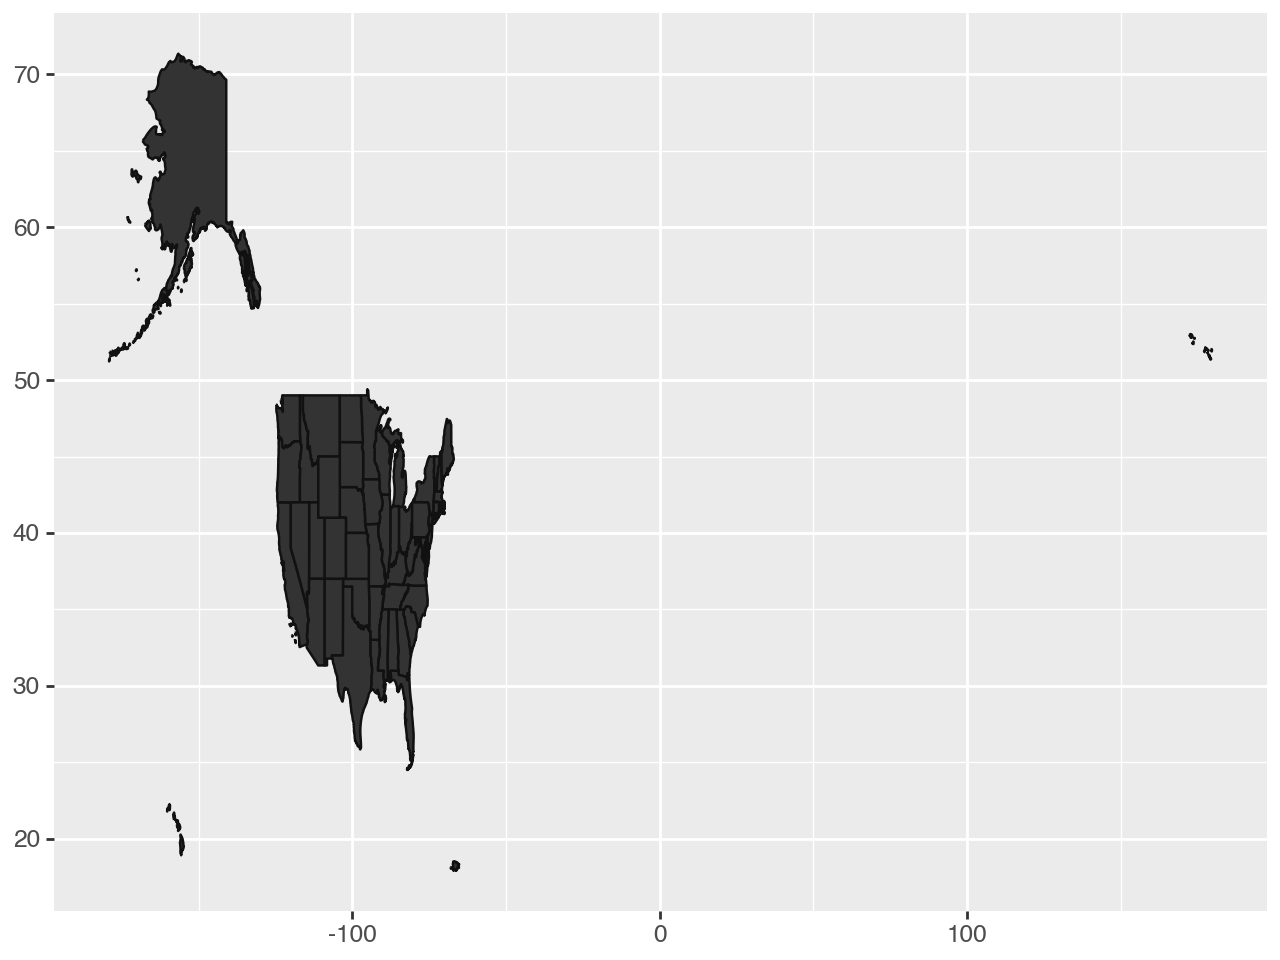

In [4]:
ggplot(data=states_gdf) + geom_map()

There are several issues:  

- the scale for latitude and longitude are skewed;
- the plot is disjointed as the Aleutian Islands in Alaska cross the 180 degree line of longitude and are plotted on the right-hand side of the map.
- Puerto Rico is included which we probably want to exclude when focusing on U.S. states.

We can easily filter the data frame to remove Puerto Rico.

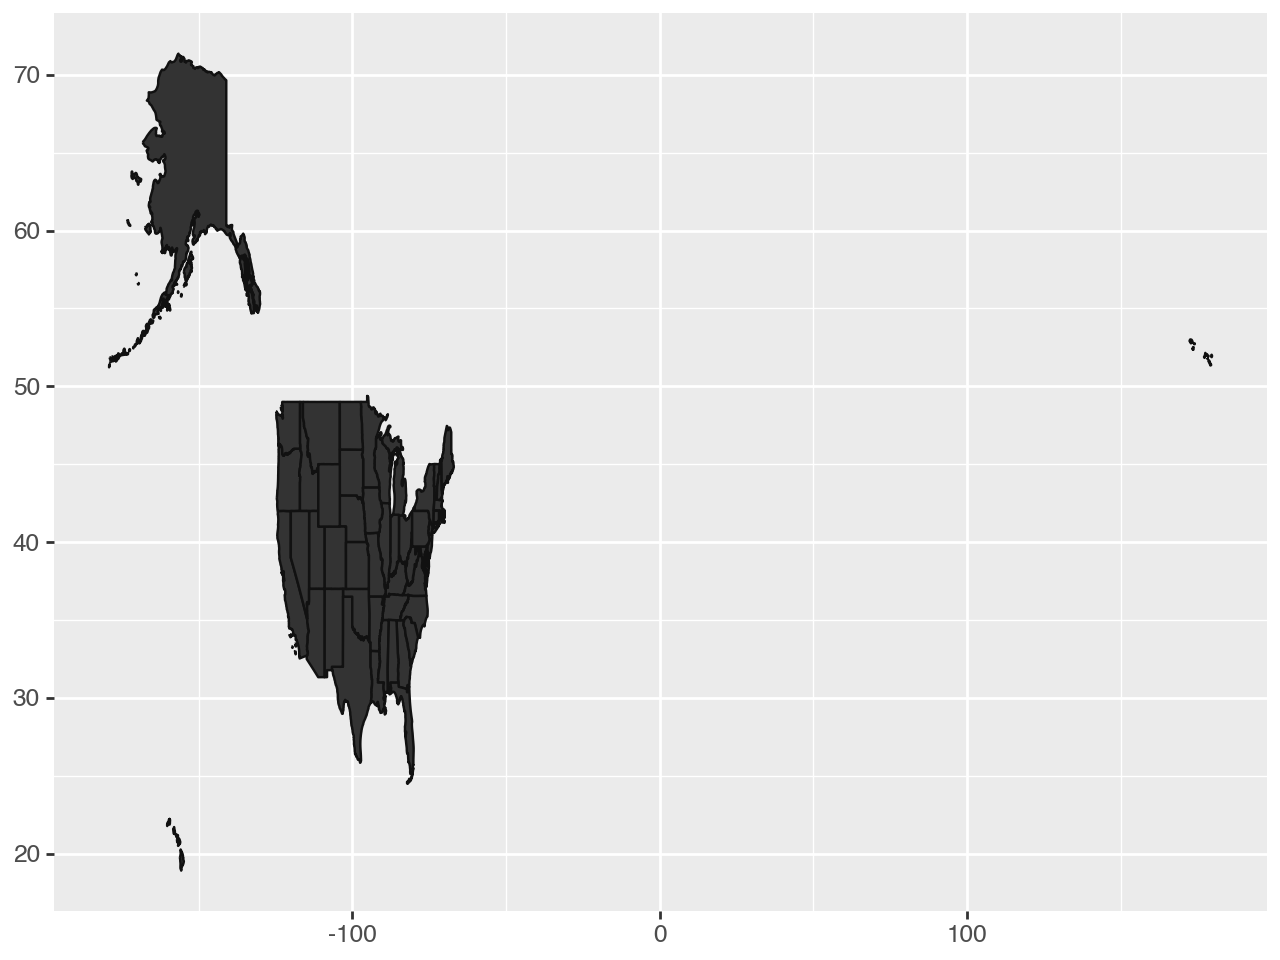

In [5]:
ggplot(data=states_gdf[states_gdf['STUSPS'] != 'PR']) + geom_map()

To fix our positioning issue, we need to review additional notes from the documentation:

>pygris includes a function, shift_geometry(), that offers an opinionated set of solutions to this problem. The function shifts and optionally rescales geometries in Alaska, Hawaii, and Puerto Rico to locations that are more appropriate for national cartographic display.

This addresses our major problems.

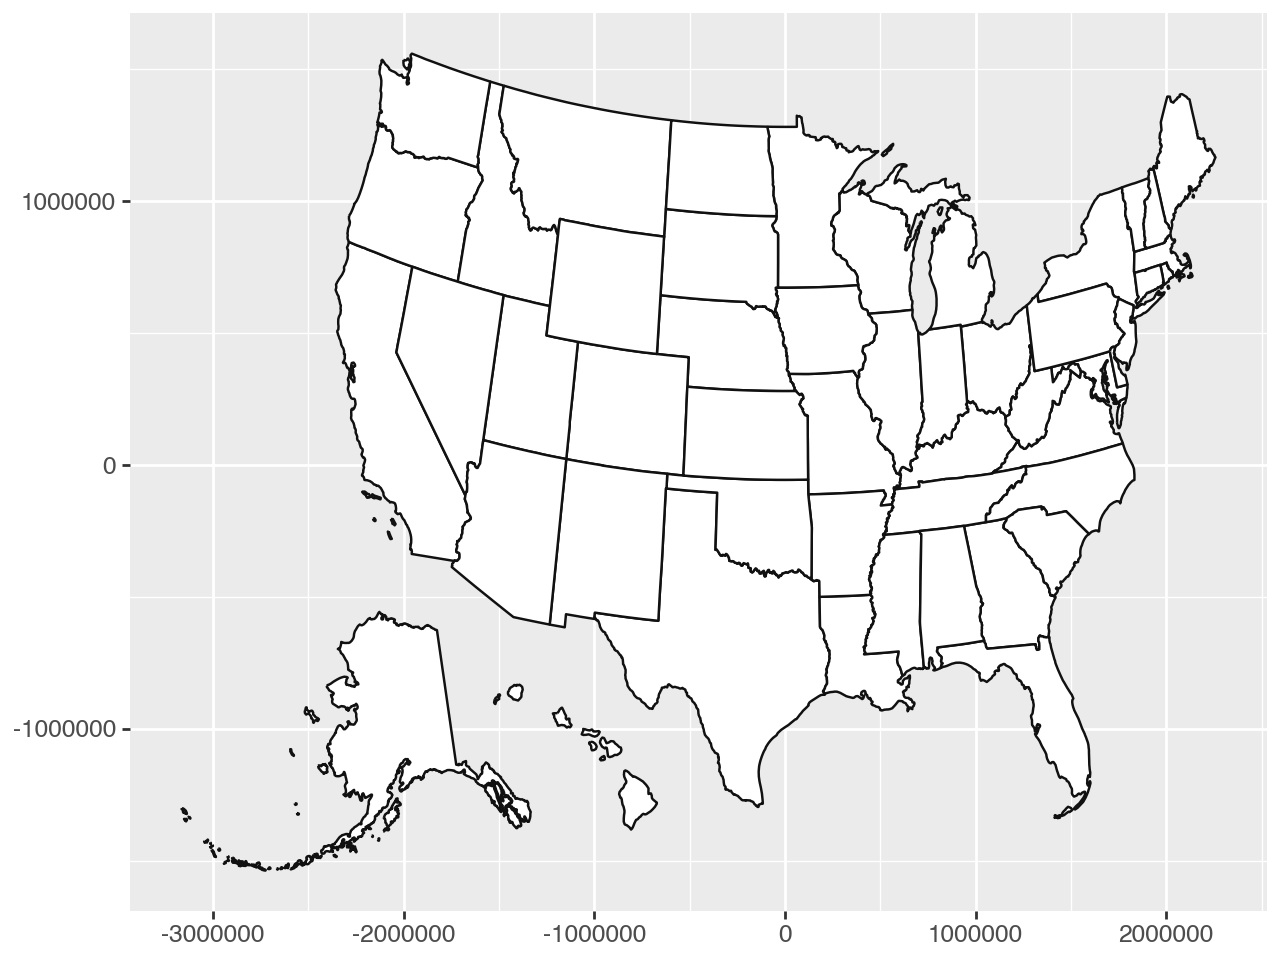

In [6]:
from pygris.utils import shift_geometry

us_gdf = shift_geometry(states_gdf[states_gdf['STUSPS'] != 'PR'])

ggplot(data=us_gdf) + geom_map(fill='white')

This is close, but the map still appears "skewed." We can add one additional layer, `coord_fixed(ratio=1)` to generate a map with the an appropriate aspect ratio.

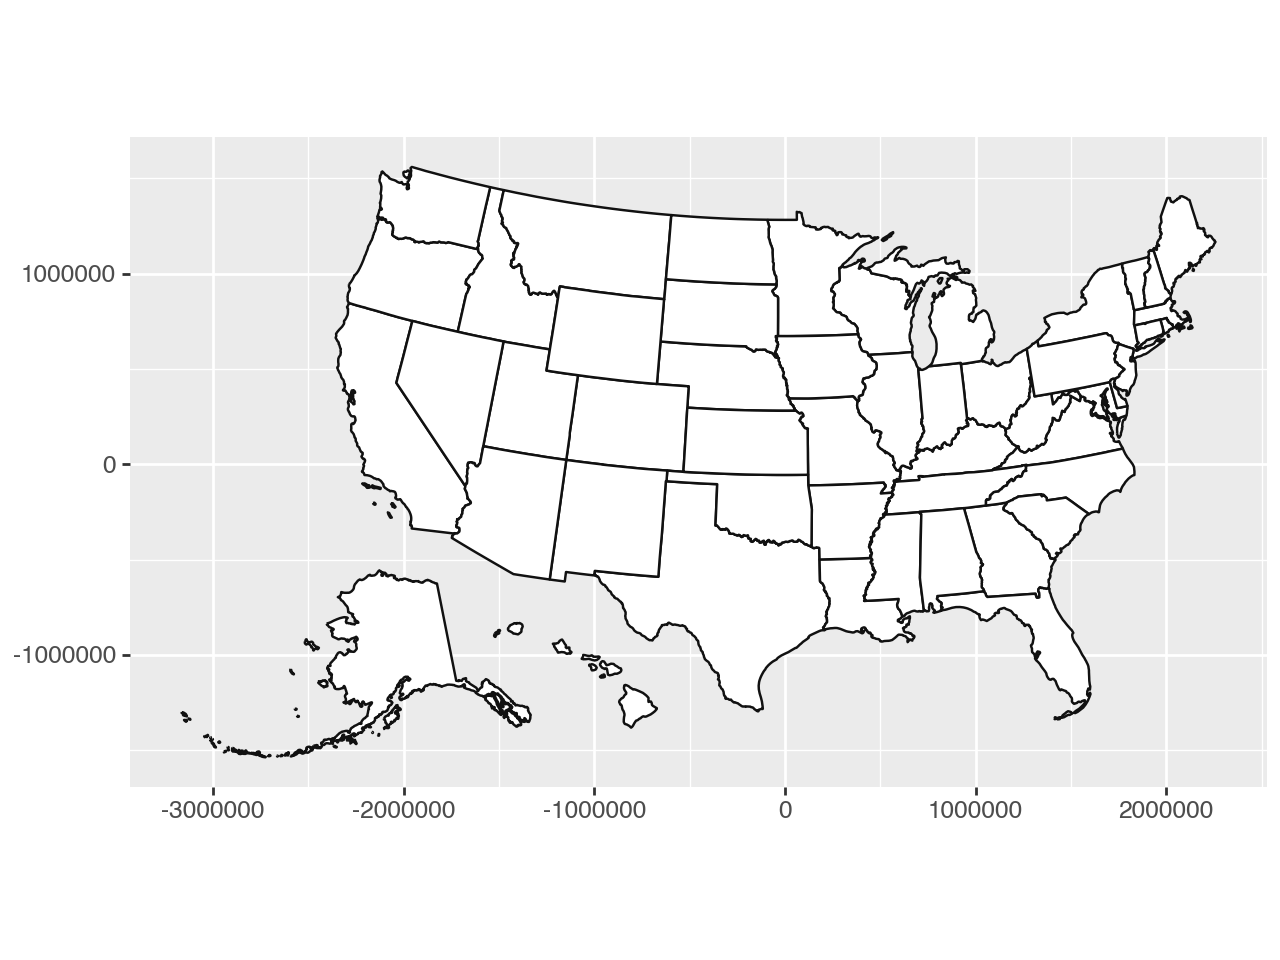

In [7]:
ggplot(data=us_gdf) + geom_map(fill='white') + coord_fixed(ratio=1)

Let's use the `crs` method to inspect the GeoPandas data frame.

In [8]:
states_gdf.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [9]:
states_gdf.crs.axis_info

[Axis(name=Geodetic latitude, abbrev=Lat, direction=north, unit_auth_code=EPSG, unit_code=9122, unit_name=degree),
 Axis(name=Geodetic longitude, abbrev=Lon, direction=east, unit_auth_code=EPSG, unit_code=9122, unit_name=degree)]

In [10]:
us_gdf.crs

<Projected CRS: ESRI:102003>
Name: USA_Contiguous_Albers_Equal_Area_Conic
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: United States (USA) - CONUS onshore - Alabama; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming.
- bounds: (-124.79, 24.41, -66.91, 49.38)
Coordinate Operation:
- name: USA_Contiguous_Albers_Equal_Area_Conic
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [11]:
us_gdf.crs.axis_info

[Axis(name=Easting, abbrev=E, direction=east, unit_auth_code=EPSG, unit_code=9001, unit_name=metre),
 Axis(name=Northing, abbrev=N, direction=north, unit_auth_code=EPSG, unit_code=9001, unit_name=metre)]

#### Key Points: Projections in GeoPandas & Plotnine

##### 1. Geographic vs. Projected CRS
* **Geographic CRS (`EPSG:4326`, `EPSG:4269`):** Coordinates are stored as curved **latitude and longitude degrees**. Raw files from the US Census (`pygris`) and standard web data usually arrive in this format.
* **Projected CRS (`EPSG:5070`, `ESRI:102003`, UTM zones):** Coordinates are flattened onto a 2D grid measured in linear units (**meters** or **feet**), using **Easting (X)** and **Northing (Y)**.

##### 2. Aligning Projections Before Plotting
* **Plotnine does not auto-reproject:** Unlike R’s `ggplot2::geom_sf()`, Plotnine’s `geom_map()` plots raw coordinate numbers directly without converting them on the fly.
* **Match all layers:** If you overlay multiple spatial layers (such as points over polygons), convert them to the exact same CRS using `.to_crs(target_gdf.crs)` so they render at the same scale.

##### 3. Fixing Aspect Ratio Distortion
* **Projected data uses `coord_fixed(1)`:** Once your data is in a flat grid (meters or feet), 1 unit on the X-axis equals 1 unit on the Y-axis, so `+ coord_fixed(1)` renders the map accurately.
* **Unprojected data stretches:** Plotting raw degrees with `coord_fixed(1)` flattens regions horizontally. Either reproject to a flat grid first (recommended) or use an approximate latitude adjustment like `coord_fixed(1.3)` for the continental US.

##### 4. Choosing the Right Projection for Choropleths
* **Use equal-area projections:** For choropleth maps, reproject to an equal-area CRS (such as **`EPSG:5070`** for the US or **`EPSG:8857`** for the world) so a region's visual size matches its true land area.
* **Watch what helper functions do:** Functions like `pygris`'s `shift_geometry()` automatically reproject unprojected Census degrees into a flat meter-based grid (`ESRI:102003`) while repositioning Alaska and Hawaii.

##### 5. Quick Inspection Commands
* **`gdf.crs`:** Displays the full projection name, EPSG/ESRI code, and coverage area.
* **`gdf.crs.axis_info`:** Confirms whether your axes are curved (`Geodetic latitude` / `degree`) or flat (`Easting` / `Northing` in `metre` or `US survey foot`).


### Step 2: Create a data frame that has the state names (or abbreviations) and population values. 

We will merge this data frame with the GeoDataFrame above.

We can manually download a dataset; however, I'm pulling U.S. Census data. You do need to register for an API key. Instructions are in the appendix below. 

In [12]:
pop_raw = get_census(
    dataset="acs/acs5",
    variables="B01003_001E",
    year=2024,
    params={
        "for": "state:*",
        "key": census_key
    },
    guess_dtypes=True,
    return_geoid=True
)

pop_raw.head()

,B01003_001E,GEOID
0,5086768,01
1,735706,02
2,7378838,04
3,3049391,05
4,39287377,06


Let's clean the above data frame and scale the population to millions.

In [13]:
pop_pl = (
    pl.from_pandas(pop_raw)
    .rename({"B01003_001E": "population"})
    .with_columns(
        (pl.col("population") / 1_000_000).alias("pop_millions")
    )
    .select(["GEOID", "pop_millions"])
)

pop_pl.head()

GEOID,pop_millions
str,f64
"""01""",5.086768
"""02""",0.735706
"""04""",7.378838
"""05""",3.049391
"""06""",39.287377


We already have our map data above, `us_gdf`. At this point we need to join our population data to the GeoPandas data frame.

In [14]:
map_pop_gdf = us_gdf[["GEOID", "NAME", "geometry"]].merge(
    pop_pl.to_pandas(),
    on="GEOID",
    how="left"
)

map_pop_gdf.head()

,GEOID,NAME,geometry,pop_millions
0,48,Texas,"POLYGON ((-998043.807 -568739.971, -997956.109...",30.188424
1,06,California,"MULTIPOLYGON (((-2066284.899 -204542.622, -205...",39.287377
2,21,Kentucky,"POLYGON ((571924.53 -84268.109, 577745.348 -84...",4.534824
3,13,Georgia,"POLYGON ((939223.082 -230281.864, 951008.202 -...",10.940407
4,55,Wisconsin,"MULTIPOLYGON (((708320.068 919586.19, 715683.6...",5.914872


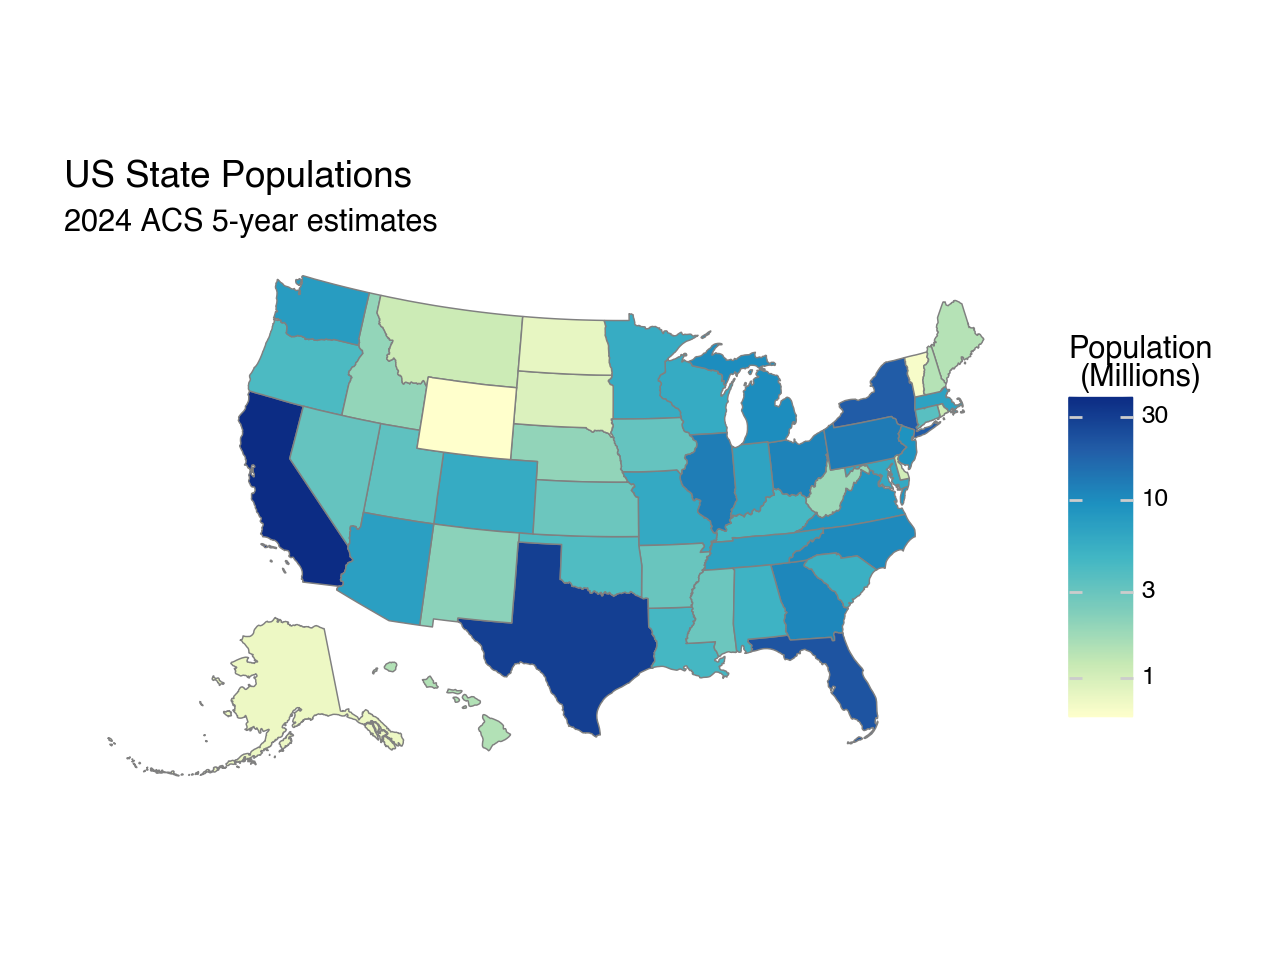

In [15]:
map_title = "US State Populations"
map_subtitle = "2024 ACS 5-year estimates"

choropleth_us_pop = (
    ggplot(map_pop_gdf)
    + geom_map(aes(fill="pop_millions"), color="gray", size=0.3)
    + coord_fixed(1)
    + labs(
        title=map_title,
        subtitle=map_subtitle
        )
    + scale_fill_distiller(
        trans="log10",
        type="seq",
        palette="YlGnBu",
        direction=1,
        name="Population\n(Millions)"
    )
    + theme_void()
    + theme(
        plot_margin=0.05
    )
)

choropleth_us_pop

# Appendix: Setting Up and Storing a US Census API Key in Python

To query data programmatically from the US Census Bureau (via packages like `pygris`), you need a free personal API key. Rather than hardcoding your key inside scripts or notebooks, store it securely as an environment variable using a `.env` file.

---

## Step 1: Request and Activate Your Census API Key
1. Go to the [US Census API Key Signup Page](https://census.gov).
2. Enter your organization name and email address, then submit the form.
3. Open the confirmation email from the Census Bureau and **click the activation link** (your key will not work until activated).

---

## Step 2: Install `python-dotenv`
In your terminal (with your project's virtual environment activated), install the `python-dotenv` package so Python can read `.env` files:

```bash
pip install python-dotenv
```

---

## Step 3: Create a `.env` File
Create a plain text file named `.env` (with no filename before the dot) in your project root folder—or in your user home directory (`~/.env`) if you want the key accessible across multiple projects.

Add your key on a single line without spaces or quotes around the `=` sign:

```text
CENSUS_API_KEY=your_40_character_api_key_here
```

> **Security Note:** If you use version control (Git/GitHub), add `.env` to your `.gitignore` file so your private key is never committed or shared publicly.

---

## Step 4: Load and Use the Key in Python
At the top of your script or Jupyter notebook, call `load_dotenv()` to load the `.env` variables into your session, then retrieve the key using `os.getenv()`:

```python
import os
from pathlib import Path
from dotenv import load_dotenv
from pygris.data import get_census

# Option A: Load from a .env file in your current project folder
load_dotenv()

# Option B: Load from a global .env file in your home folder (~/.env)
# load_dotenv(Path.home() / ".env")

# Retrieve the API key
census_key = os.getenv("CENSUS_API_KEY")

# Pass the key into your Census API request
pop_raw = get_census(
    dataset="acs/acs5",
    variables="B01003_001E",
    year=2023,
    params={
        "for": "state:*",
        "key": census_key
    },
    guess_dtypes=True,
    return_geoid=True
)
```

---

## Quick Troubleshooting
* **`census_key` returns `None`:** Verify that your file is named `.env` (not `.env.txt`), there are no spaces around `=`, and you restarted your notebook kernel after creating the file.
* **`JSONDecodeError` or invalid key message:** Double-check that you clicked the activation link in your Census signup email.
